In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r'C:\Users\malik\Downloads\data-analysis-2023-labs-master\data-analysis-2023-labs-master\input\olympics-economics.csv'
)

df.head()

,country,country_code,gold,silver,bronze,total,gdp,gdp_year,population
0,United States,USA,40,44,42,126,81695.19,2023,334.9
1,China,CHN,40,27,24,91,12614.06,2023,1410.7
2,Japan,JPN,20,12,13,45,33834.39,2023,124.5
3,Australia,AUS,18,19,16,53,64711.77,2023,26.6
4,France,FRA,16,26,22,64,44460.82,2023,68.2


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country       90 non-null     str    
 1   country_code  90 non-null     str    
 2   gold          90 non-null     int64  
 3   silver        90 non-null     int64  
 4   bronze        90 non-null     int64  
 5   total         90 non-null     int64  
 6   gdp           90 non-null     float64
 7   gdp_year      90 non-null     int64  
 8   population    90 non-null     float64
dtypes: float64(2), int64(5), str(2)
memory usage: 6.5 KB


In [3]:
# Ustunlar nomini ko‘rish
print(df.columns)

# Har bir ustundagi bo‘sh qiymatlar soni
print(df.isnull().sum())

Index(['country', 'country_code', 'gold', 'silver', 'bronze', 'total', 'gdp',
       'gdp_year', 'population'],
      dtype='str')
country         0
country_code    0
gold            0
silver          0
bronze          0
total           0
gdp             0
gdp_year        0
population      0
dtype: int64


In [4]:
df.describe()

,gold,silver,bronze,total,gdp,gdp_year,population
count,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000
mean,3.644444,3.633333,4.255556,11.533333,24478.053556,2022.977778,69.027778
std,7.018933,6.797967,6.586607,19.782071,25547.857382,0.148231,213.286437
min,0.000000,0.000000,0.000000,1.000000,1014.210000,2022.000000,0.100000
25%,0.000000,0.000000,1.000000,2.000000,5815.180000,2023.000000,5.325000
50%,1.000000,1.000000,2.000000,5.000000,13061.185000,2023.000000,12.150000
75%,3.000000,3.000000,5.000000,9.000000,34484.677500,2023.000000,48.550000
max,40.000000,44.000000,42.000000,126.000000,103684.880000,2023.000000,1428.600000


In [5]:
# O'zgaruvchilar orasidagi korrelatsiya
df[['total', 'gdp', 'population']].corr()

,total,gdp,population
total,1.000000,0.347942,0.393278
gdp,0.347942,1.000000,-0.112182
population,0.393278,-0.112182,1.000000


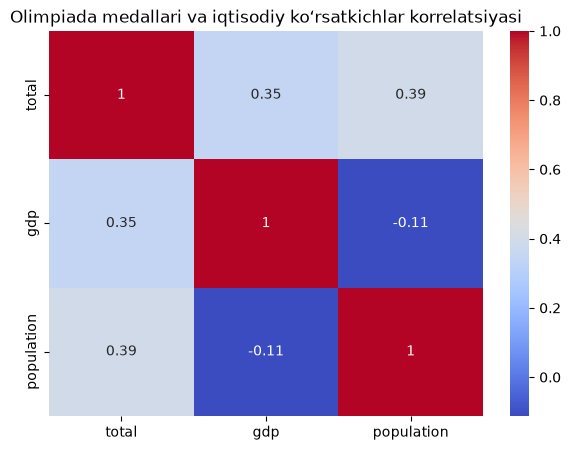

In [6]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[['total', 'gdp', 'population']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Olimpiada medallari va iqtisodiy ko‘rsatkichlar korrelatsiyasi')
plt.show()

In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
X = df[['gdp']]
Y = df['total']

In [10]:
lm = LinearRegression()

In [11]:
lm.fit(X, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['gdp']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.939
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [12]:
print("Intercept:", lm.intercept_)
print("Coefficient:", lm.coef_)

Intercept: 4.938550779503886
Coefficient: [0.00026942]


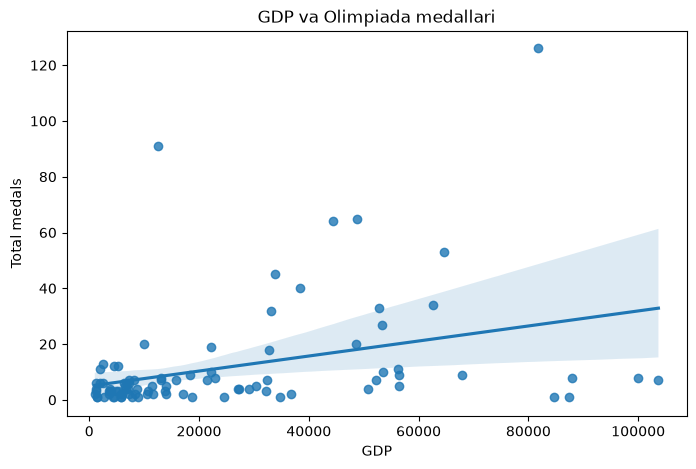

In [13]:
plt.figure(figsize=(8, 5))

sns.regplot(data=df, x='gdp', y='total')

plt.title('GDP va Olimpiada medallari')
plt.xlabel('GDP')
plt.ylabel('Total medals')
plt.show()

In [14]:
Y_pred = lm.predict(X)

In [15]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(Y, Y_pred)

print("MSE:", mse)

MSE: 340.13286217936087


In [16]:
from sklearn.metrics import r2_score

r2 = r2_score(Y, Y_pred)

print("R-squared:", r2)

R-squared: 0.12106333922481449


In [17]:
X = df[['gdp', 'population']]
Y = df['total']

In [18]:
lm_multi = LinearRegression()

In [19]:
lm_multi.fit(X, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0. ,0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['gdp','population']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.205
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [20]:
print("Intercept:", lm_multi.intercept_)
print("Coefficients:", lm_multi.coef_)

Intercept: 1.204587571338818
Coefficients: [0.00030745 0.04060737]


In [21]:
Y_multi_pred = lm_multi.predict(X)

mse_multi = mean_squared_error(Y, Y_multi_pred)
r2_multi = r2_score(Y, Y_multi_pred)

print("MSE:", mse_multi)
print("R-squared:", r2_multi)

MSE: 266.8869366593819
R-squared: 0.31033799142813434


In [22]:
from sklearn.preprocessing import PolynomialFeatures

In [23]:
X = df[['gdp']]
Y = df['total']

In [24]:
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

In [25]:
lm_poly = LinearRegression()

lm_poly.fit(X_poly, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0., 0.,-0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.8376
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[2.11e+10,7.70e+04,0.00e+00]"


In [26]:
Y_poly_pred = lm_poly.predict(X_poly)

mse_poly = mean_squared_error(Y, Y_poly_pred)
r2_poly = r2_score(Y, Y_poly_pred)

print("MSE:", mse_poly)
print("R-squared:", r2_poly)

MSE: 326.3691148341077
R-squared: 0.1566302116930527


In [27]:
X = df[['gdp', 'population']]
Y = df['total']

In [28]:
poly_multi = PolynomialFeatures(degree=2)

X_poly_multi = poly_multi.fit_transform(X)

In [29]:
poly_multi = PolynomialFeatures(degree=2)

X_poly_multi = poly_multi.fit_transform(X)

In [30]:
lm_poly_multi = LinearRegression()

lm_poly_multi.fit(X_poly_multi, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0., 0.,-0.,-0., 0.,-0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.1454
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[2.11e+10,3.18e+07,2.46e+06,7.59e+04,3.69e+02,0.00e+00]"


In [31]:
Y_poly_multi_pred = lm_poly_multi.predict(X_poly_multi)

In [32]:
mse_poly_multi = mean_squared_error(Y, Y_poly_multi_pred)
r2_poly_multi = r2_score(Y, Y_poly_multi_pred)

print("MSE:", mse_poly_multi)
print("R-squared:", r2_poly_multi)

MSE: 78.43704833852527
R-squared: 0.797310977522158


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [34]:
Input = [('scale', StandardScaler()),
         ('polynomial', PolynomialFeatures(degree=2)),
         ('model', LinearRegression())]

pipe = Pipeline(Input)

In [35]:
pipe.fit(X, Y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('polynomial', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['gdp','population']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [36]:
Y_pipeline_pred = pipe.predict(X)

In [37]:
mse_pipeline = mean_squared_error(Y, Y_pipeline_pred)
r2_pipeline = r2_score(Y, Y_pipeline_pred)

print("MSE:", mse_pipeline)
print("R-squared:", r2_pipeline)

MSE: 77.5758375709288
R-squared: 0.7995364305743706


In [38]:
new_data = pd.DataFrame({
    'gdp': [20000],
    'population': [50]
})

In [39]:
prediction = pipe.predict(new_data)

print("Bashorat qilingan medallar soni:", prediction[0])

Bashorat qilingan medallar soni: 13.573292673723234


In [40]:
predicted_medals = round(prediction[0])

print("Kutilayotgan jami medallar soni:", predicted_medals)

Kutilayotgan jami medallar soni: 14


In [41]:
results = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression',
        'Multivariate Polynomial Regression',
        'Pipeline'
    ],
    'MSE': [
        mse,
        mse_multi,
        mse_poly,
        mse_poly_multi,
        mse_pipeline
    ],
    'R-squared': [
        r2,
        r2_multi,
        r2_poly,
        r2_poly_multi,
        r2_pipeline
    ]
})

results

,Model,MSE,R-squared
0,Simple Linear Regression,340.132862,0.121063
1,Multiple Linear Regression,266.886937,0.310338
2,Polynomial Regression,326.369115,0.156630
3,Multivariate Polynomial Regression,78.437048,0.797311
4,Pipeline,77.575838,0.799536


In [42]:
print("Pipeline MSE:", mse_pipeline)
print("Pipeline R-squared:", r2_pipeline)

Pipeline MSE: 77.5758375709288
Pipeline R-squared: 0.7995364305743706


In [43]:
results = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression',
        'Multivariate Polynomial Regression',
        'Pipeline'
    ],
    'MSE': [
        mse,
        mse_multi,
        mse_poly,
        mse_poly_multi,
        mse_pipeline
    ],
    'R-squared': [
        r2,
        r2_multi,
        r2_poly,
        r2_poly_multi,
        r2_pipeline
    ]
})

results.sort_values(by='R-squared', ascending=False)

,Model,MSE,R-squared
4,Pipeline,77.575838,0.799536
3,Multivariate Polynomial Regression,78.437048,0.797311
1,Multiple Linear Regression,266.886937,0.310338
2,Polynomial Regression,326.369115,0.156630
0,Simple Linear Regression,340.132862,0.121063
